# Experimento 1 - Configuración del entrenamiento
Objetivo:

Entrenar únicamente una pequeña parte de SAM2 para adaptarlo a imágenes Sentinel‑2.

Capas entrenables:

* transformer.layers[1]
* iou_prediction_head

Capas congeladas:

* encoder
* resto del decoder

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image

from google.colab import drive

# URL de repositorio
!git clone https://github.com/ZagonTM/Sen4Sam
# Una vez clonado, nos movemos al directorio del repositorio o lo añadimos al path
import os
if os.path.exists('Sen4Sam'):
    %cd Sen4Sam
    print("Acceso al repositorio Sen4Sam exitoso.")
else:
    print("No se pudo encontrar la carpeta del repositorio. Verifica la URL de clonación.")

# Instalar Segment Anything 2 (SAM 2) y sus dependencias
!pip install -q git+https://github.com/facebookresearch/sam2.git

# Crear directorio de checkpoints y descargar los pesos del modelo
!mkdir -p checkpoints
!wget -P checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

ROOT = Path.cwd()

DATA_ROOT = Path(
    "/content/drive/MyDrive/Sen4SAM"
)

PROCESSED = (
    DATA_ROOT /
    "processed" /
    "processed"
)

sys.path.insert(
    0,
    str(ROOT / "src")
)
from sam2_auto_segment import build_model

model = build_model()



Cloning into 'Sen4Sam'...
remote: Enumerating objects: 145, done.
remote: Counting objects: 100% (145/145), done.
remote: Compressing objects: 100% (102/102), done.
remote: Total 145 (delta 63), reused 106 (delta 40), pack-reused 0 (from 0)
Receiving objects: 100% (145/145), 3.56 MiB | 18.21 MiB/s, done.
Resolving deltas: 100% (63/63), done.
/content/Sen4Sam
Acceso al repositorio Sen4Sam exitoso.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
--2026-11-08 18:01:37--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 3.171.22.33, 3.171.22.13, 3.17

In [2]:
for p in model.parameters():
    p.requires_grad = False

In [3]:
last_block = (
    model.sam_mask_decoder
    .transformer
    .layers[1]
)

iou_head = (
    model.sam_mask_decoder
    .iou_prediction_head
)

In [4]:
for p in last_block.parameters():
    p.requires_grad = True

for p in iou_head.parameters():
    p.requires_grad = True

In [5]:
trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(trainable)

1712132


# Experimento 2 - Reconstrucción del pipeline interno
Objetivo:

Generar máscaras utilizando directamente los módulos internos de SAM2, manteniendo el grafo computacional.

In [7]:
def load_rgb(patch):

    return np.array(
        Image.open(
            DATA_ROOT / "processed"/ "processed" / f"{patch}_rgb.png"
        ).convert("RGB")
    )
def load_parcels(patch):

    return np.load(
        DATA_ROOT / "processed"/ "processed" / f"{patch}_parcels.npy"
    )

from google.colab import drive

drive.mount('/content/drive')

gt_dataset = pd.read_csv(
    DATA_ROOT / "gt_parcel_dataset.csv"
)

train_df = gt_dataset.sample(
    200,
    random_state=42
)


row = train_df.iloc[0]

image = load_rgb(
    row["patch"]
)

Mounted at /content/drive


In [10]:
from sam2.sam2_image_predictor import SAM2ImagePredictor

predictor = SAM2ImagePredictor(model)

predictor.set_image(image)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [11]:
image_embed = (
    predictor._features[
        "image_embed"
    ]
)

high_res_feats = (
    predictor._features[
        "high_res_feats"
    ]
)

In [12]:
image_pe = (
    model.sam_prompt_encoder
    .get_dense_pe()
)

Prompt

In [13]:
# Las parcelas estan en pixeles del parche (366x366); SAM espera coordenadas en su marco de 1024x1024.
# transform_coords normaliza por (alto, ancho) y escala a 1024 (igual que predictor.predict).
point_coords = predictor._transforms.transform_coords(
    torch.tensor([[[row["cx"], row["cy"]]]], dtype=torch.float32,
                 device=image_embed.device),
    normalize=True,
    orig_hw=(366, 366)
)

point_labels = torch.tensor(
    [[1]],
    dtype=torch.int64,
    device=image_embed.device
)

Prompt encoder

In [14]:
sparse_embeddings, dense_embeddings = (
    model.sam_prompt_encoder(
        points=(
            point_coords,
            point_labels
        ),
        boxes=None,
        masks=None
    )
)

Decoder

In [15]:
masks, iou_pred, mask_tokens, obj_logits = (
    model.sam_mask_decoder.predict_masks(

        image_embeddings=image_embed,

        image_pe=image_pe,

        sparse_prompt_embeddings=sparse_embeddings,

        dense_prompt_embeddings=dense_embeddings,

        repeat_image=False,

        high_res_features=high_res_feats
    )
)

# Experimento 3 - Supervisión parcelaria
Objetivo:

Comparar las máscaras generadas por el decoder con las parcelas reales de Sen4AgriNet.

In [17]:
def load_parcel_mask(
    patch,
    parcel_id
):

    parcels = np.load(
        PROCESSED /
        f"{patch}_parcels.npy"
    )

    return (
        parcels == parcel_id
    ).astype(np.float32)

gt_mask = load_parcel_mask(
    row["patch"],
    row["parcel_id"]
)
print(gt_mask.shape)

print(gt_mask.dtype)

print(gt_mask.sum())

(366, 366)
float32
91.0


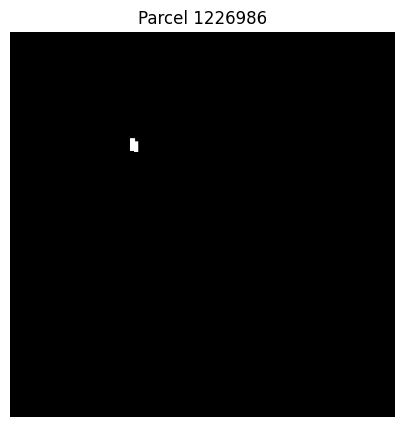

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))

plt.imshow(
    gt_mask,
    cmap="gray"
)

plt.title(
    f"Parcel {row['parcel_id']}"
)

plt.axis("off")

plt.show()

Tensor

In [21]:
gt_mask = torch.tensor(
    gt_mask,
    dtype=torch.float32,
    device=image_embed.device
)

gt_mask = gt_mask.unsqueeze(0).unsqueeze(0)

Ajustar tamaño

In [22]:
import torch.nn.functional as F

gt_mask = F.interpolate(
    gt_mask,
    size=(
        masks.shape[-2],
        masks.shape[-1]
    ),
    mode="nearest"
)

Probabilidades

In [23]:
pred_probs = torch.sigmoid(
    masks[:,0:1]
)

Dice

In [32]:
def dice_loss(
    pred,
    target,
    eps=1e-6
):

    pred = pred.reshape(-1)

    target = target.reshape(-1)

    inter = (
        pred * target
    ).sum()

    dice = (
        2 * inter + eps
    ) / (
        pred.sum()
        + target.sum()
        + eps
    )

    return 1 - dice


Loss

In [33]:
loss = dice_loss(
    pred_probs,
    gt_mask
)

print(loss)

tensor(0.9975, grad_fn=<RsubBackward1>)


# Experimento 4 - Backpropagation
Objetivo:

Comprobar que la pérdida puede propagarse hasta los parámetros entrenables.

Optimazer

In [34]:
optimizer = torch.optim.Adam(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=1e-4
)

Paso de entrenamiento

In [35]:
optimizer.zero_grad()

loss.backward()

optimizer.step()

Verificacion critica

In [36]:
print(

    next(
        last_block.parameters()
    ).grad.norm()

)

tensor(0.0007)


# Conclusiones
## Experimento 1
Se configuró una intervención ligera sobre SAM2.

Capas entrenables:

* transformer.layers[1]
* iou_prediction_head

Parámetros entrenables:

* 1,712,132
* 3.72 % del modelo
## Experimento 2
Se reconstruyó la ruta interna completa:

RGB Image → image_embed → Prompt Encoder → Mask Decoder → Masks

evitando la API de inferencia basada en NumPy.

## Experimento 3
Se definió una función Dice Loss utilizando parcelas reales de Sen4AgriNet.

Esto proporciona supervisión directa sobre segmentación agrícola.

## Experimento 4
Se verificó la propagación de gradientes.

Resultado:

gradient norm = 0.0007

Esto confirma que la pérdida alcanza los módulos seleccionados para adaptación.

## Conclusión General
La intervención propuesta es funcional.

Se dispone de un pipeline de entrenamiento completo capaz de adaptar representaciones internas del decoder utilizando supervisión parcelaria directa.

La siguiente etapa consiste en entrenar durante múltiples épocas y comparar el rendimiento frente a la línea base establecida en la Fase A.